# Regression - Credit Card Data

**Goal:** predict `Amount` from `V1` to `V28` using Simple, Multiple and Polynomial regression.

`Amount` is already scaled in `creditcard_clean.csv`. Low R2 is expected, because the V features were not made to predict Amount.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = pd.read_csv('../Data/creditcard_clean.csv')

## Pick the best feature (highest correlation with Amount)

In [3]:
v_cols = ['V' + str(i) for i in range(1, 29)]

corr = data[v_cols + ['Amount']].corr()['Amount'].drop('Amount')
best_feat = corr.abs().idxmax()

print(corr.abs().sort_values(ascending=False).head(5))
print('Best feature:', best_feat)

V2     0.533428
V7     0.400408
V5     0.387685
V20    0.340729
V1     0.230105
Name: Amount, dtype: float64
Best feature: V2


## Train-test split

In [4]:
x = data[v_cols]
y = data['Amount']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## 1. Simple Linear Regression (one feature)

R2 score: 0.30410296618371757


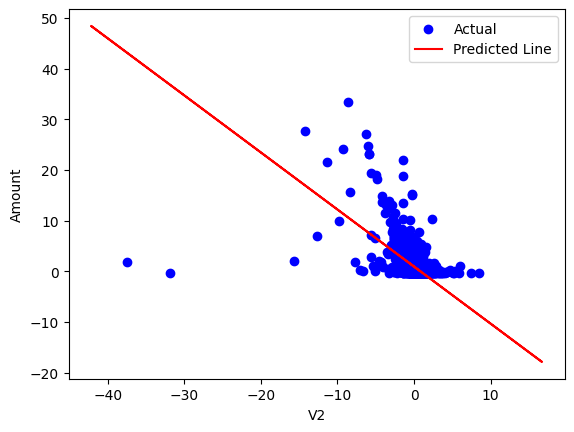

In [5]:
model = LinearRegression()
model.fit(x_train[[best_feat]], y_train)
y_pred = model.predict(x_test[[best_feat]])

print('R2 score:', r2_score(y_test, y_pred))

plt.scatter(x_test[best_feat][:2000], y_test[:2000], color='blue', label='Actual')
plt.plot(x_test[best_feat], y_pred, color='red', label='Predicted Line')
plt.xlabel(best_feat)
plt.ylabel('Amount')
plt.legend()
plt.show()

## 2. Multiple Linear Regression (all V features)

In [6]:
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print('R2 score:', r2_score(y_test, y_pred))

R2 score: 0.916833976214606


## 3. Polynomial Regression (degree 2, best feature)

In [7]:
x1_train = x_train[[best_feat]]
x1_test = x_test[[best_feat]]

poly = PolynomialFeatures(degree=2)
x_train_trans = poly.fit_transform(x1_train)
x_test_trans = poly.transform(x1_test)

model = LinearRegression()
model.fit(x_train_trans, y_train)
y_pred = model.predict(x_test_trans)

print('R2 train:', r2_score(y_train, model.predict(x_train_trans)))
print('R2 test :', r2_score(y_test, y_pred))

R2 train: 0.29887473070599735
R2 test : 0.3250440395609676


c:\Users\NITISH RANA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


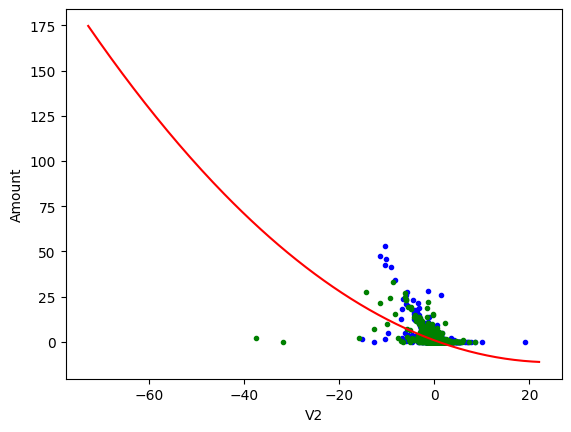

In [8]:
x_new = np.linspace(x1_train[best_feat].min(), x1_train[best_feat].max(), 200).reshape(200, 1)
y_new = model.predict(poly.transform(x_new))

plt.plot(x1_train[best_feat][:2000], y_train[:2000], 'b.')
plt.plot(x1_test[best_feat][:2000], y_test[:2000], 'g.')
plt.plot(x_new, y_new, 'r-')
plt.xlabel(best_feat)
plt.ylabel('Amount')
plt.show()

## Conclusion
- R2 is low in all three models, so the V features explain only a small part of Amount.
- Polynomial regression improves the fit very little over the straight line.
- The main task for this dataset is classification (fraud or not).